# Notebook 11 – EDA Visualization

**Dataset:** Telco Customer Churn Dataset

This notebook uses Matplotlib and Seaborn to create meaningful visualizations for understanding numerical and categorical features, feature relationships, distributions, and customer churn patterns.

Each visualization is selected based on the type of data and the relationship that needs to be analyzed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


In [2]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    "gender",
    "Partner",
    "Dependents",
    "Contract",
    "PaymentMethod",
    "InternetService",
    "Churn"
]

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'Contract', 'PaymentMethod', 'InternetService', 'Churn']


# Question 1 – Histogram

##  How can a Histogram be used to understand numerical data?

### Step 1: Why is this visualization selected?

A histogram is selected to understand the distribution of a numerical variable.

It helps identify:

- Frequency of values
- Distribution shape
- Concentration of observations
- Possible skewness
- Possible extreme values

### Step 2: Generate the Visualization

We create histograms for important numerical features such as `tenure`, `MonthlyCharges`, and `TotalCharges`.

### Step 3: Interpret the Visualization

The x-axis represents the numerical values and the y-axis represents their frequency.

The shape of the histogram helps us understand how the values are distributed.

### Step 4: Insight

The histogram helps identify whether customers are concentrated around certain ranges and whether the numerical variables show skewed distributions.

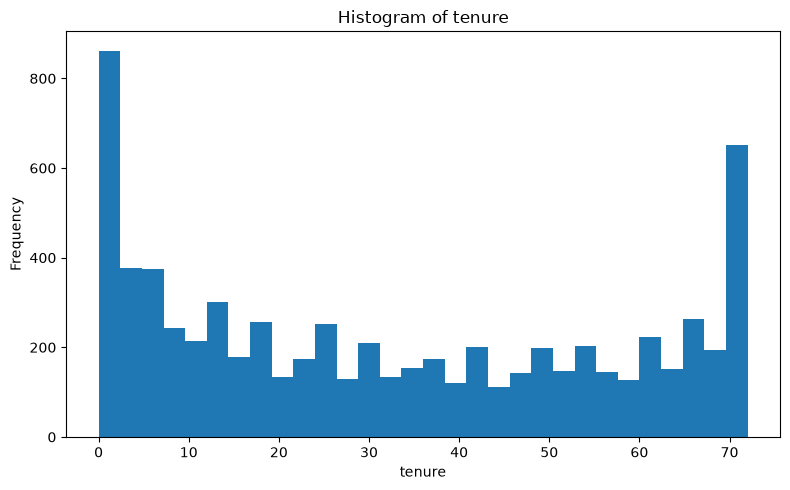

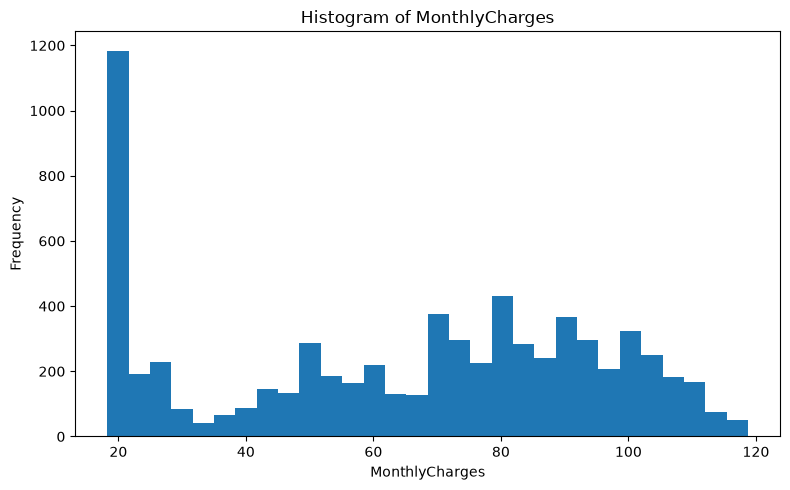

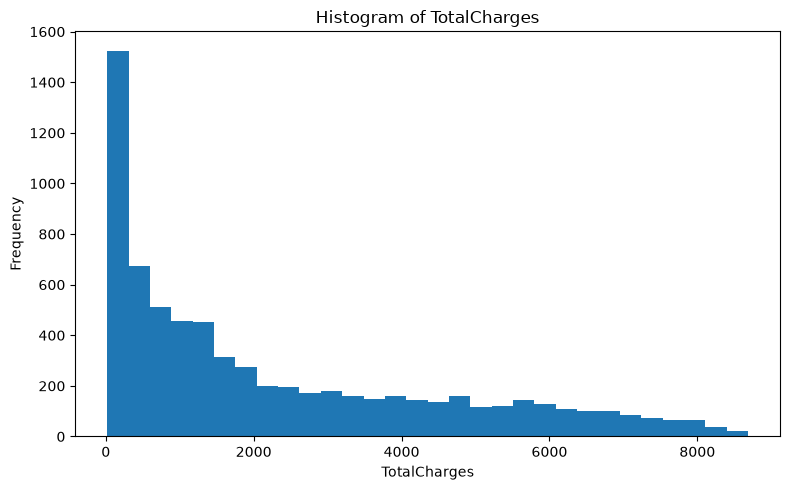

In [3]:
for column in numerical_features:

    plt.figure(figsize=(8, 5))

    plt.hist(
        df[column].dropna(),
        bins=30
    )

    plt.title(f"Histogram of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

# Question 2 – Box Plot


##  How can a Box Plot be used to identify spread and outliers?

### Step 1: Why is this visualization selected?

A box plot is selected to understand:

- Median
- Quartiles
- Interquartile Range
- Spread
- Potential outliers

### Step 2: Generate the Visualization

We create box plots for the important numerical features.

### Step 3: Interpret the Visualization

The box represents the middle 50% of the observations.

Points outside the whiskers may represent potential outliers.

### Step 4: Insight

The box plot helps identify unusual values and compare the spread of numerical features.

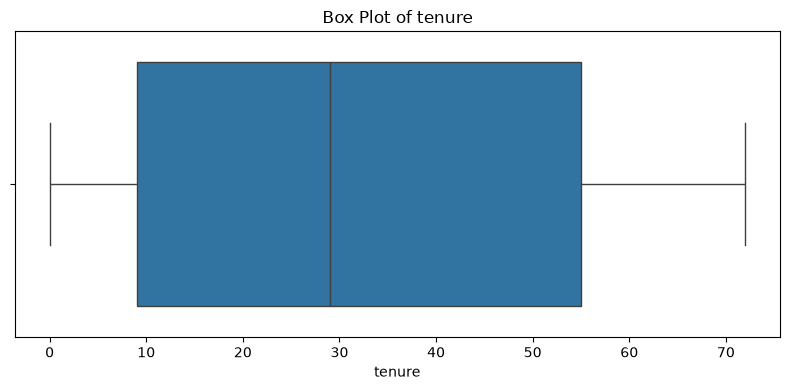

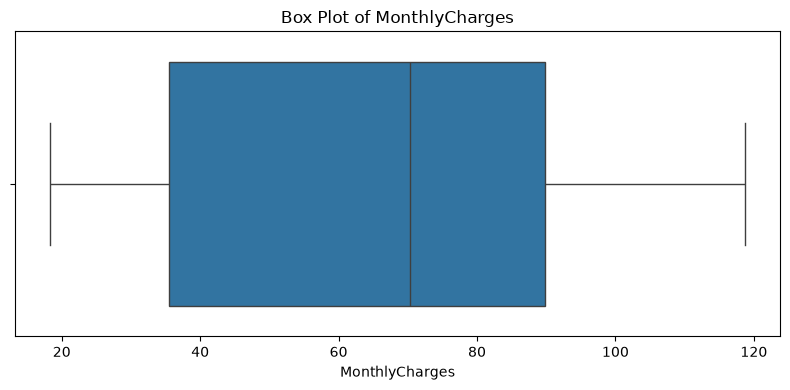

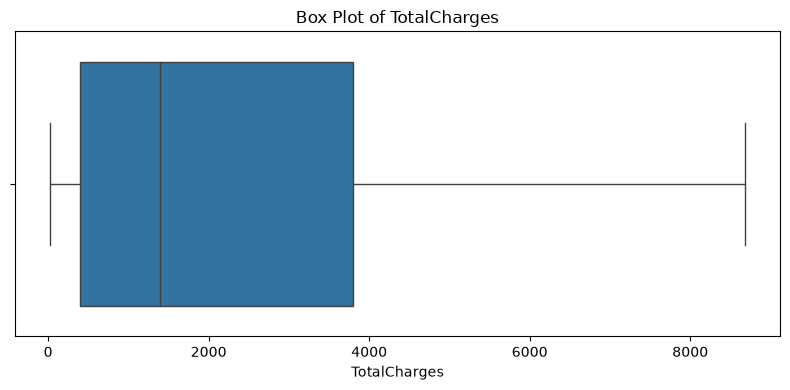

In [4]:
for column in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column].dropna())

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

# Question 3 – Bar Chart



## How can a Bar Chart be used to compare categories?

### Step 1: Why is this visualization selected?

A bar chart is selected to compare the frequency of different categories.

It is useful for categorical variables such as `Contract`.

### Step 2: Generate the Visualization

We compare the number of customers in each contract type.

### Step 3: Interpret the Visualization

The height of each bar represents the number of customers belonging to that category.

### Step 4: Insight

The chart helps identify which contract type is most common among customers.

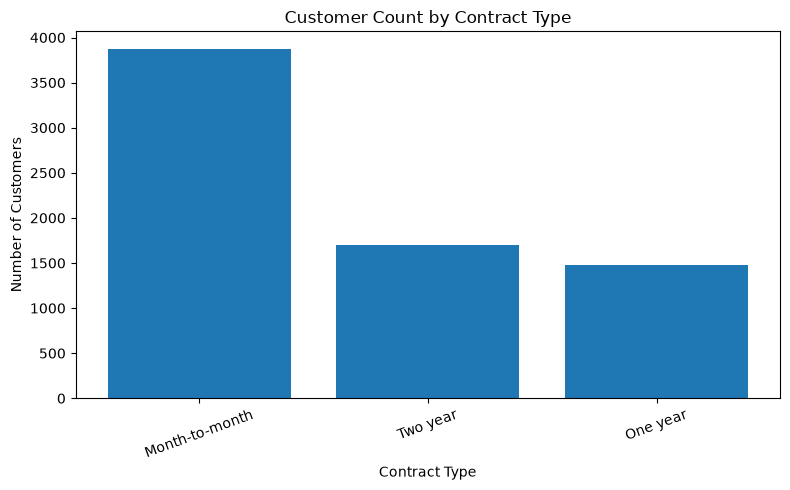

In [5]:
contract_counts = df["Contract"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    contract_counts.index,
    contract_counts.values
)

plt.title("Customer Count by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Question 4 – Count Plot

##  How can a Count Plot be used to analyze Churn?

### Step 1: Why is this visualization selected?

A count plot is selected because `Churn` is a categorical target variable.

It directly displays the number of customers in each Churn class.

### Step 2: Generate the Visualization

We visualize the number of customers who churned and did not churn.

### Step 3: Interpret the Visualization

The height of each bar represents the number of customers in that class.

### Step 4: Insight

The visualization helps identify the majority and minority classes of the target variable.

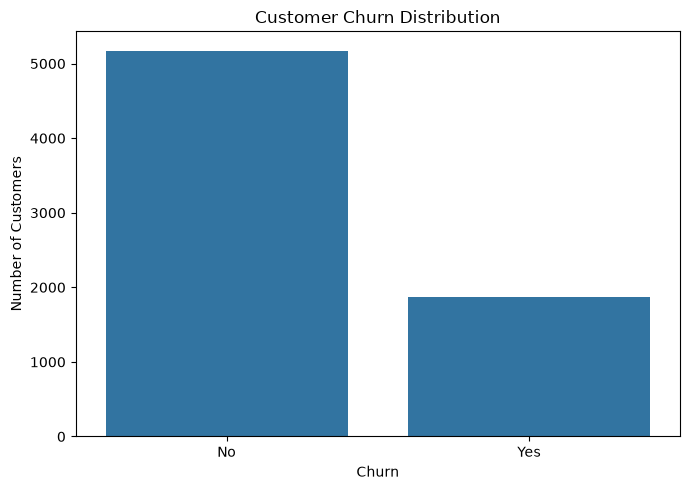

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

# Question 5 – Scatter Plot


## How can a Scatter Plot be used to analyze numerical relationships?

### Step 1: Why is this visualization selected?

A scatter plot is selected to examine the relationship between two numerical variables.

Here, we analyze `tenure` and `TotalCharges`.

### Step 2: Generate the Visualization

Each point represents a customer.

### Step 3: Interpret the Visualization

The position of each point represents the customer's tenure and total charges.

A visible upward pattern indicates that TotalCharges tends to increase as tenure increases.

### Step 4: Insight

The visualization helps identify relationships, patterns, clusters, and unusual observations between numerical features.

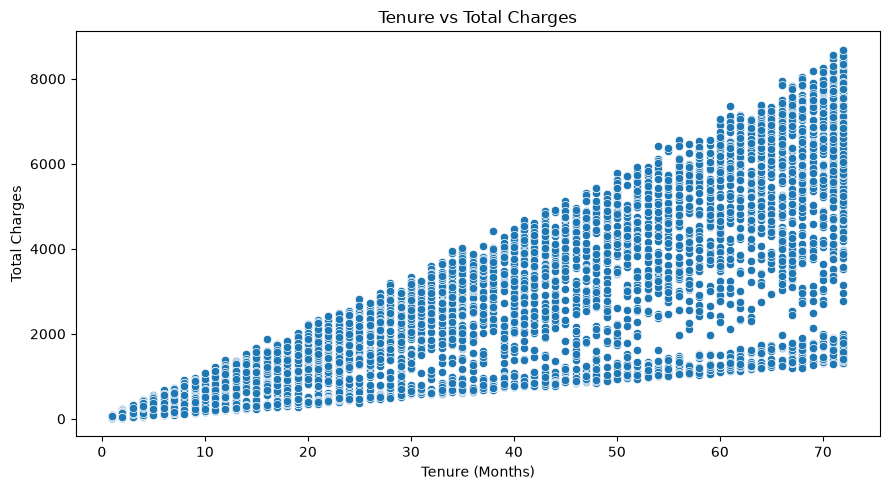

In [7]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges"
)

plt.title("Tenure vs Total Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")

plt.tight_layout()
plt.show()

# Question 6 – Line Plot


##  How can a Line Plot be used to analyze trends?

### Step 1: Why is this visualization selected?

A line plot is selected to show how a numerical measure changes across an ordered variable.

Here, we calculate the average MonthlyCharges for different tenure values.

### Step 2: Generate the Visualization

We group customers by tenure and calculate their average MonthlyCharges.

### Step 3: Interpret the Visualization

The line shows how the average monthly charge changes as customer tenure increases.

### Step 4: Insight

The visualization helps identify possible trends between customer tenure and average monthly charges.

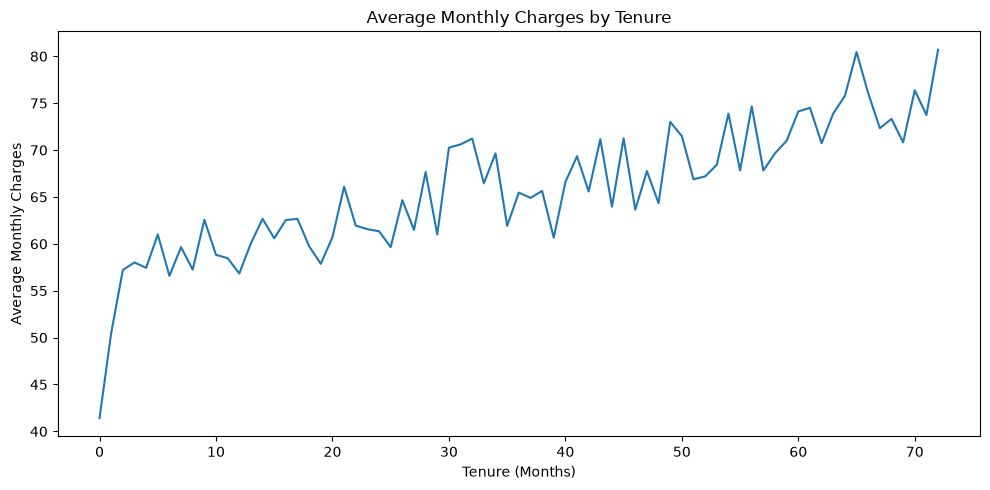

In [8]:
tenure_charges = (
    df.groupby("tenure")["MonthlyCharges"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    tenure_charges["tenure"],
    tenure_charges["MonthlyCharges"]
)

plt.title("Average Monthly Charges by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Average Monthly Charges")

plt.tight_layout()
plt.show()

# Question 7 – Violin Plot


## How can a Violin Plot compare numerical distributions across categories?

### Step 1: Why is this visualization selected?

A violin plot is selected because it shows both:

- Distribution shape
- Spread of numerical values

We compare `MonthlyCharges` across different `Contract` types.

### Step 2: Generate the Visualization

Each violin represents the distribution of MonthlyCharges for a contract category.

### Step 3: Interpret the Visualization

The width of the violin represents the density of observations at different values.

### Step 4: Insight

The visualization helps compare the distribution and concentration of monthly charges across contract types.

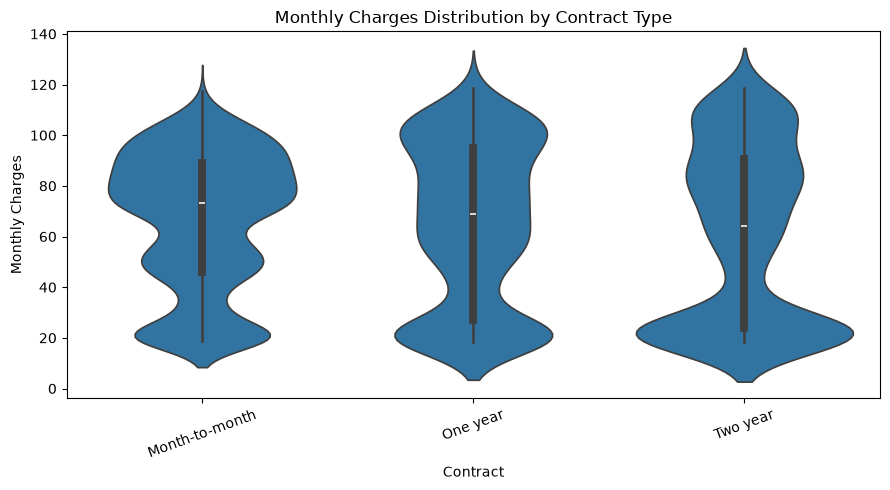

In [9]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="Contract",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Monthly Charges")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Question 8 – Pair Plot


## How can a Pair Plot be used to analyze multiple numerical relationships?

### Step 1: Why is this visualization selected?

A pair plot is selected to examine relationships between multiple numerical features at the same time.

We analyze:

- Tenure
- MonthlyCharges
- TotalCharges

### Step 2: Generate the Visualization

The pair plot creates scatter plots for feature pairs and distributions along the diagonal.

### Step 3: Interpret the Visualization

The scatter plots show relationships between numerical features.

The diagonal plots show the individual distributions of the features.

### Step 4: Insight

The pair plot provides an overall view of numerical feature relationships and can help identify strong relationships or unusual patterns.

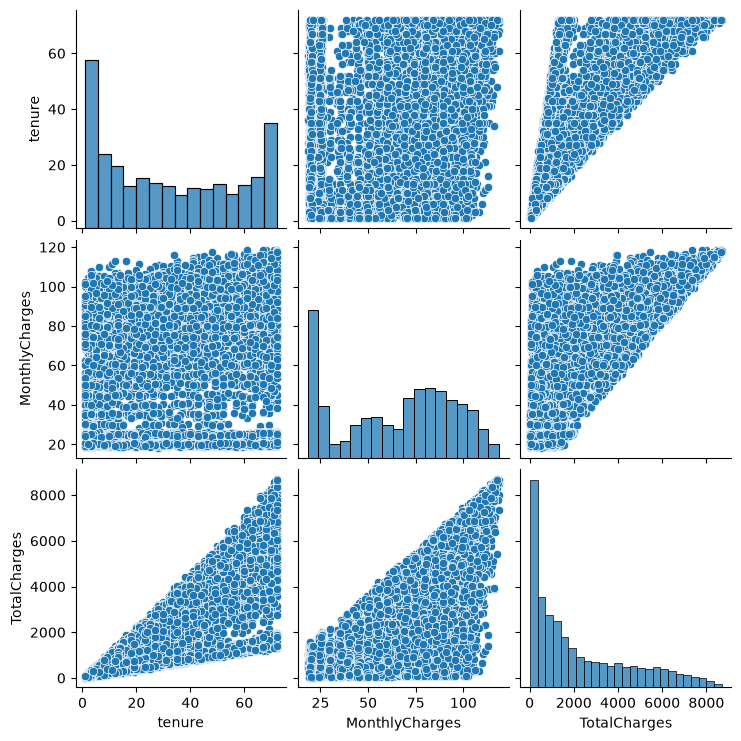

In [10]:
pairplot_data = df[numerical_features].dropna()

sns.pairplot(pairplot_data)

plt.show()

# Question 9 – Heatmap


##  How can a Heatmap be used to analyze correlations?

### Step 1: Why is this visualization selected?

A heatmap is selected to visualize the correlation between numerical features.

It makes strong and weak relationships easier to identify.

### Step 2: Generate the Visualization

We calculate the correlation matrix and display it using a heatmap.

### Step 3: Interpret the Visualization

Correlation values range from -1 to +1.

- Values close to +1 → Strong positive relationship
- Values close to -1 → Strong negative relationship
- Values close to 0 → Weak linear relationship

### Step 4: Insight

The heatmap helps identify important numerical relationships and possible multicollinearity between features.

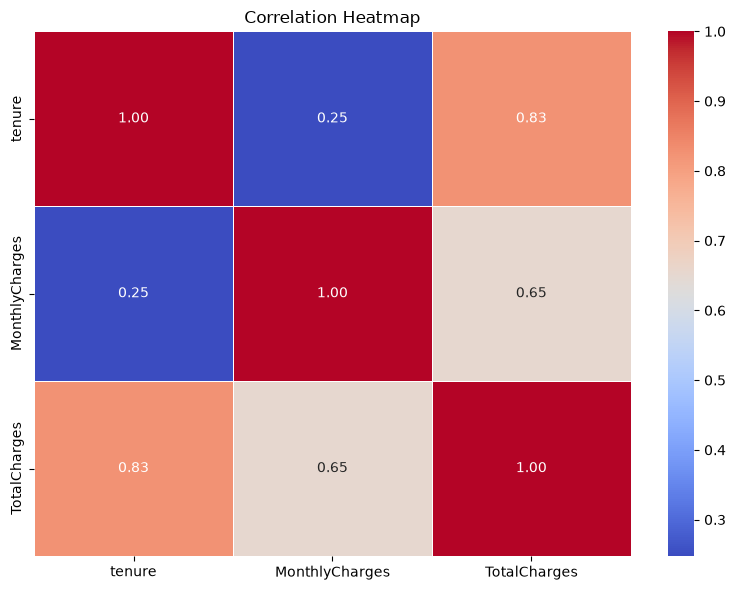

In [11]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()


# Question 10 – Distribution Plot


##  How can a Distribution Plot be used to understand numerical data?

### Step 1: Why is this visualization selected?

A distribution plot is selected to understand the shape and density of a numerical variable.

It helps identify:

- Center
- Spread
- Distribution shape
- Skewness
- Concentration of values

### Step 2: Generate the Visualization

We use a KDE-based distribution plot for the numerical features.

### Step 3: Interpret the Visualization

The curve represents the density of observations across different values.

### Step 4: Insight

The distribution plot helps identify whether the numerical variables are approximately symmetric or skewed.

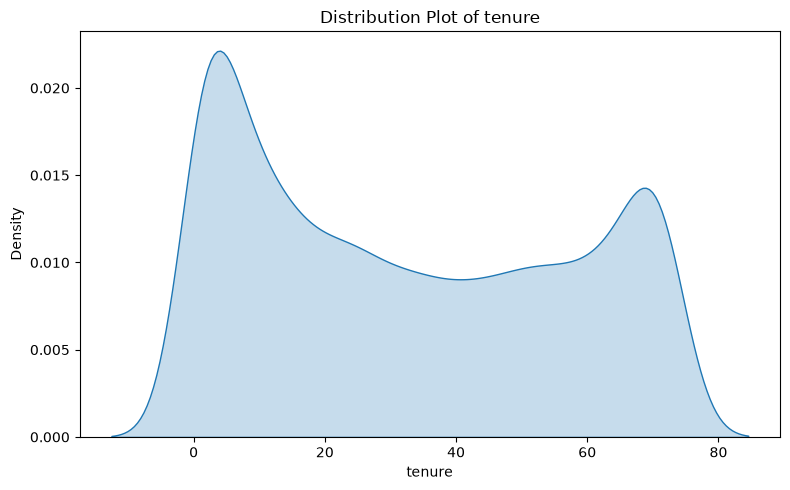

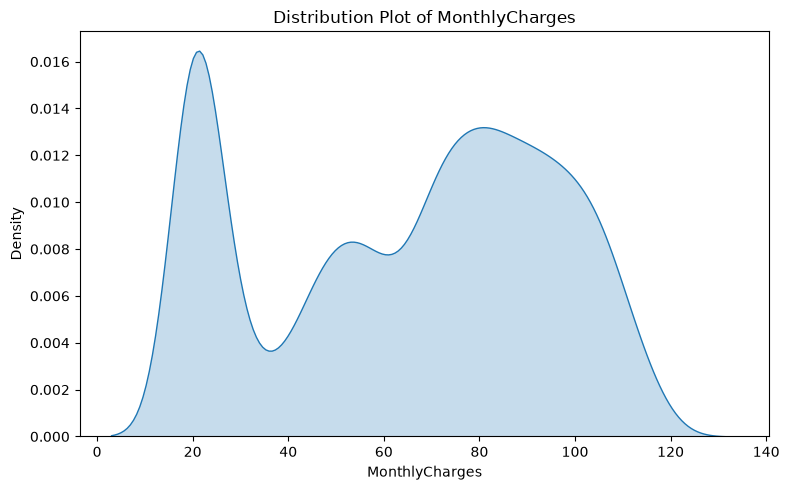

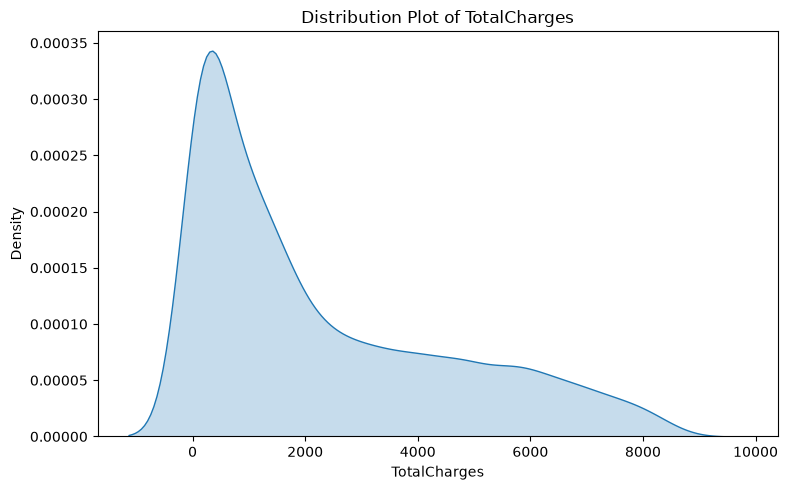

In [12]:
for column in numerical_features:

    data = df[column].dropna()

    plt.figure(figsize=(8, 5))

    sns.kdeplot(
        x=data,
        fill=True
    )

    plt.title(f"Distribution Plot of {column}")
    plt.xlabel(column)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

# Question 11 – Visualization Based on Churn


##  How can Visualization be used to analyze Churn-related patterns?

### Step 1: Why is this visualization selected?

A count plot with `hue="Churn"` is selected to compare customer churn across important categorical features.

Here, we analyze `Contract` because contract type may show different churn patterns.

### Step 2: Generate the Visualization

We compare each contract type according to Churn status.

### Step 3: Interpret the Visualization

The bars show how many customers in each contract category stayed or churned.

### Step 4: Insight

This visualization helps identify whether churn patterns differ across contract types.

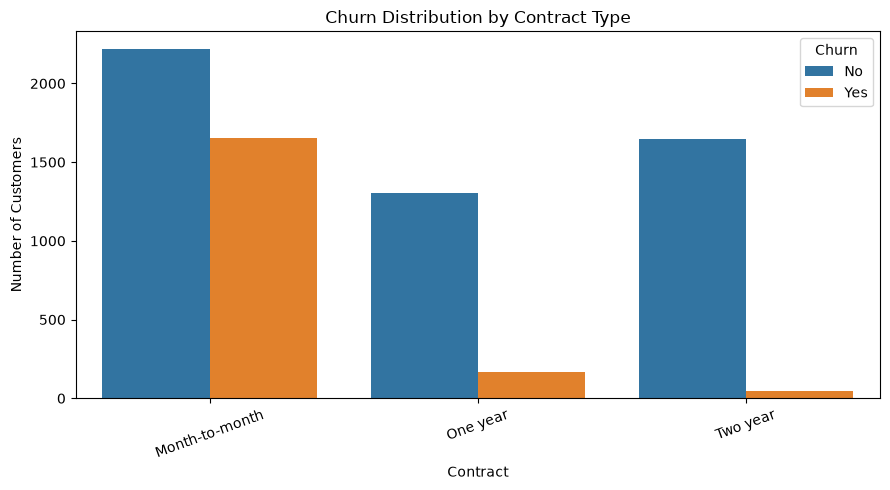

In [13]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn Distribution by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Question 12 – Select Meaningful Visualizations


## Why should we avoid creating graphs without purpose?

### Step 1: Understand

EDA visualizations should answer a specific analytical question.

A graph should be created only when it helps us understand:

- Distribution
- Comparison
- Relationship
- Trend
- Outliers
- Correlation
- Category differences

### Step 2: Demonstrate

Examples:

- Histogram → Understand numerical distribution
- Box Plot → Detect spread and potential outliers
- Bar Chart → Compare category frequencies
- Count Plot → Analyze categorical counts
- Scatter Plot → Study numerical relationships
- Line Plot → Identify trends
- Violin Plot → Compare distributions across categories
- Pair Plot → Analyze multiple numerical relationships
- Heatmap → Analyze correlations
- Distribution Plot → Understand density and shape

### Step 3: Implementation

The visualizations in this notebook were selected based on the type of data and the analytical question being answered.

### Step 4: Insight

Meaningful visualization makes EDA easier to understand and helps identify patterns that may not be obvious from numerical summaries alone.

## Final Findings

The EDA visualization analysis used Matplotlib and Seaborn to understand the Telco Customer Churn dataset.

The following visualizations were created based on meaningful analytical purposes:

1. Histogram – Analyzed numerical feature distributions.
2. Box Plot – Examined spread and potential outliers.
3. Bar Chart – Compared customer counts across contract categories.
4. Count Plot – Analyzed the Churn class distribution.
5. Scatter Plot – Examined the relationship between Tenure and TotalCharges.
6. Line Plot – Analyzed the trend of average MonthlyCharges across tenure.
7. Violin Plot – Compared MonthlyCharges distributions across contract types.
8. Pair Plot – Examined relationships among numerical features.
9. Heatmap – Analyzed correlations between numerical features.
10. Distribution Plot – Examined the density and shape of numerical variables.

These visualizations help identify distributions, relationships, trends, category differences, correlations, and potential outliers.

The graphs were selected based on specific EDA questions rather than being created simply for visualization purposes.